In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import NaturalEarthFeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER
import dask
import glob
from dask.distributed import Client, progress

import sys
sys.path.append('/home/561/nm5072/MHW_sandbox')
import bipolarMhwToolBox as MHW

%matplotlib inline

In [2]:
client = Client(processes=True, threads_per_worker=1,memory_limit="32GB")
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 14
Total threads: 14,Total memory: 417.23 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33003,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36175,Total threads: 1
Dashboard: /proxy/37717/status,Memory: 29.80 GiB
Nanny: tcp://127.0.0.1:39115,


ERROR:asyncio:Task exception was never retrieved
future: <Task finished name='Task-1542101' coro=<Client._gather.<locals>.wait() done, defined at /g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/client.py:2377> exception=AllExit()>
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/client.py", line 2386, in wait
    raise AllExit()
distributed.client.AllExit
ERROR:asyncio:Task exception was never retrieved
future: <Task finished name='Task-1542098' coro=<Client._gather.<locals>.wait() done, defined at /g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/client.py:2377> exception=AllExit()>
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/client.py", line 2386, in wait
    raise AllExit()
distributed.client.AllExit
ERRO

### Function to calculate severity and SSTA

In [3]:
def compute_severity(temp, Seas, Thresh, keep_ssta=False):
    """
    Compute anomaly (ssta) and severity according to the MHW definition used 
    in the bipolarMhwToolBox.

    Parameters
    ----------
    temp : xr.DataArray
        Daily temperature time series (float32 recommended).
    Seas : xr.DataArray
        Seasonal climatology (same grid as temp).
    Thresh : xr.DataArray
        Threshold (e.g., 90th percentile) climatology.
    keep_ssta : bool, default False
        If True, also return ssta as a DataArray.

    Returns
    -------
    severity : xr.DataArray
        Severity = (temp - Seas) / (Thresh - Seas)
        Non-MHW days may still have values <1; masking is left to the user.
    ssta (optional) : xr.DataArray
        Temp minus climatology.
    """

    # Align everything safely without broadcasting surprises
    temp, Seas, Thresh = xr.align(temp, Seas, Thresh, join="exact")

    # Compute anomaly
    ssta = (temp - Seas).astype("float32")

    # Compute severity
    severity = (ssta / (Thresh - Seas)).astype("float32")

    if keep_ssta:
        return xr.Dataset(
            {
                "severity": severity,
                "ssta": ssta,
            },
            coords=temp.coords,
        )
    else:
        return severity

## load datasets

In [4]:
ds = xr.open_dataset('/scratch/m35/nm5072/oisst_1988-2018_rechunk_spat90.zarr',chunks={},consolidated=False)
seas   = xr.open_dataset(
    '/scratch/m35/nm5072/oisst_1988-2018_global_seas.nc',
    chunks={"time": -1, "lat": 90, "lon": 90},
)

thresh = xr.open_dataset(
    '/scratch/m35/nm5072/oisst_1988-2018_global_thresh.nc',
    chunks={"time": -1, "lat": 90, "lon": 90},
)

In [5]:
from dask.diagnostics import ProgressBar

# 1. Prepare Climatologies (Load small arrays to Cluster RAM)
# We persist these so Dask doesn't re-read the netcdfs for every chunk
seas_clim = seas.sst.persist()
thresh_clim = thresh.sst.persist()

# 2. Define the Full Index
# We use the full time index from the original dataset (10,958 days)
full_doy_index = ds.sst.time.dt.dayofyear

# 3. Create "Virtual" Expanded Climatologies
# This assumes the shape of the full dataset
seas_full = seas_clim.sel(dayofyear=full_doy_index)
thresh_full = thresh_clim.sel(dayofyear=full_doy_index)

# 4. Alignment and Cleanup
# Drop the repeating 1-366 index and replace with the actual dates
seas_full = seas_full.drop_vars('dayofyear').assign_coords(time=ds.sst.time)
thresh_full = thresh_full.drop_vars('dayofyear').assign_coords(time=ds.sst.time)

# Transpose to match ds.sst structure: (time, zlev, lat, lon)
seas_full = seas_full.transpose('time', 'zlev', 'lat', 'lon')
thresh_full = thresh_full.transpose('time', 'zlev', 'lat', 'lon')

# 5. THE MOST IMPORTANT STEP: Re-chunking
# We force the expanded climatology to match the chunking of the SST data.
# SST is chunked (10958, 1, 90, 90). We must match this.
chunk_map = {'time': -1, 'lat': 90, 'lon': 90, 'zlev': 1}

seas_full = seas_full.chunk(chunk_map)
thresh_full = thresh_full.chunk(chunk_map)

# 6. Define the Computation
# This sets up the graph but runs nothing yet.
# We set keep_ssta=True so you get both Severity and Anomaly.
severity_ds = compute_severity(ds.sst, seas_full, thresh_full, keep_ssta=True)

# 7. Execute and Save to Disk
# Choose a location on your scratch space
output_path = '/scratch/m35/nm5072/oisst_1988-2018_severity_full.zarr'

print(f"Starting full calculation. Saving to: {output_path}")
print("Watch the Dask Dashboard (Status Page) now...")

with ProgressBar():
    severity_ds.to_zarr(output_path, mode='w', consolidated=True)

print("Done!")

Starting full calculation. Saving to: /scratch/m35/nm5072/oisst_1988-2018_severity_full.zarr
Watch the Dask Dashboard (Status Page) now...


/g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/dask/_task_spec.py:764: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/dask/_task_spec.py:764: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)


Done!


In [ ]:
# Plot a random point to make sure the time series looks correct
# This checks if the seasonality was subtracted correctly.
point_sev = severity_subset.isel(lat=300, lon=300, zlev=0)

plt.figure(figsize=(12, 6))
point_sev['severity'].plot(label='SSTA')
plt.axhline(0, color='k', linewidth=0.5)
plt.title("Test SSTA at one location (2010-2011)")
plt.legend()

In [6]:
tst = xr.open_dataset('/scratch/m35/nm5072/oisst_1988-2018_severity_full.zarr')

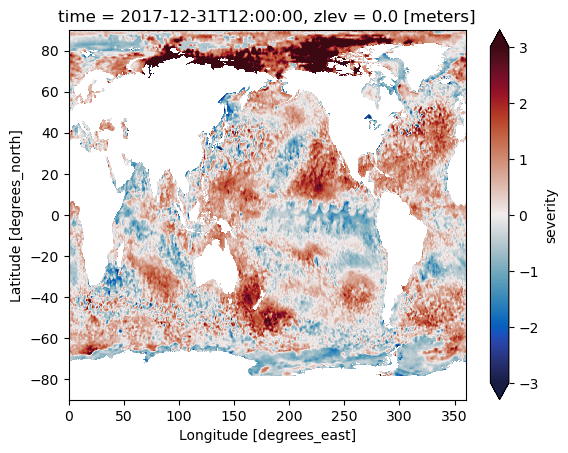

In [12]:
tst.severity.isel(time=-1).plot(vmin=-3, vmax=3,cmap=cmo.balance)

### Now get MHW metrics

In [13]:
# 1. Load the Severity Zarr (Computed in the previous step)
# We use consolidated=True for faster loading of metadata
input_path = '/scratch/m35/nm5072/oisst_1988-2018_severity_full.zarr'
ds_sev = xr.open_zarr(input_path, consolidated=True)

# Check chunking - it should be (10958, 1, 90, 90) or similar
print(f"Input chunks: {ds_sev.chunks}")

Input chunks: Frozen({'time': (10958,), 'zlev': (1,), 'lat': (90, 90, 90, 90, 90, 90, 90, 90), 'lon': (90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90)})


In [14]:
# 2. Calculate MHW Metrics
# The function expects 'ds' to contain 'ssta' and 'severity'.
# Since we used keep_ssta=True previously, ds_sev has both.
# maxEvt=200 allows for up to 200 events per pixel over the 30-year period.
print("Defining MHW computation graph...")

ds_metrics = MHW.calculate_MHWs_metrics(ds_sev, maxEvt=200)

Defining MHW computation graph...


In [15]:
# 3. Clean up Dimensions (Optional but recommended)
# The output will have dims (variable, event, zlev, lat, lon).
# If zlev is 1, we can squeeze it out to make the file smaller/cleaner.
if 'zlev' in ds_metrics.dims:
    ds_metrics = ds_metrics.squeeze('zlev')

In [16]:
# 4. Save Metrics to Disk
# We save to a new Zarr file. 
output_path = '/scratch/m35/nm5072/oisst_1988-2018_mhw_events.zarr'

print(f"Starting computation. Saving to: {output_path}")

# This will trigger the actual computation.
# Since the input is chunked by time=-1, Dask will process this 
# one spatial tile at a time (embarrassingly parallel).
with ProgressBar():
    ds_metrics.to_zarr(output_path, mode='w', consolidated=True)

print("MHW Event detection complete.")

Starting computation. Saving to: /scratch/m35/nm5072/oisst_1988-2018_mhw_events.zarr


2025-12-10 12:28:36,304 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('vectorize_add_metrics_MHWs-vectorize_add_metrics_MHWs_0-8d00c274de25412e6502e61c040b6f4f', 0, 7, 0, 0, 0))" coro=<Worker.execute() done, defined at /g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/worker_state_machine.py:3607>> ended with CancelledError
2025-12-10 12:28:36,305 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('vectorize_add_metrics_MHWs-vectorize_add_metrics_MHWs_0-8d00c274de25412e6502e61c040b6f4f', 0, 6, 6, 0, 0))" coro=<Worker.execute() done, defined at /g/data/xp65/public/apps/med_conda/envs/analysis3-25.08/lib/python3.11/site-packages/distributed/worker_state_machine.py:3607>> ended with CancelledError
2025-12-10 12:28:36,305 - distributed.worker.state_machine - WARNING - Async instruction for <Task cancelled name="execute(('vectorize_add_metrics

KeyboardInterrupt: 